# 3B. Autoencoder - ECG (substitute for MVTec AD)
Dense autoencoder on ECG5000. Train on normal class, detect anomalies via reconstruction error.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import roc_auc_score, classification_report

In [2]:
df = pd.read_csv("../datasets/AutoEncoder/ECG/ecg.csv", header=None)
data = df.to_numpy()

x = data[:, :-1].astype("float32")
y = (data[:, -1] != 1).astype(int)  # label 1 = normal, else anomaly

x_min = x.min()
x_max = x.max()
x = (x - x_min) / (x_max - x_min)

x_train_norm = x[y == 0]
print("normal:", x_train_norm.shape, "anomalies:", y.sum())

normal: (2919, 140) anomalies: 2079


In [3]:
model = keras.Sequential([
    layers.Input(shape=(140,)),
    layers.Dense(64, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(16, activation="relu"),
    layers.Dense(32, activation="relu"),
    layers.Dense(64, activation="relu"),
    layers.Dense(140),
])
model.compile(optimizer="adam", loss="mse")
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         9,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 140)            │         9,100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,388 (91.36 KB)

 Trainable params: 23,388 (91.36 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train_norm, x_train_norm, epochs=20, validation_split=0.1)

Epoch 1/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.0435 - val_loss: 0.0011
Epoch 2/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 812us/step - loss: 0.0010 - val_loss: 9.9944e-04
Epoch 3/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 769us/step - loss: 0.0010 - val_loss: 9.7893e-04
Epoch 4/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step - loss: 0.0010 - val_loss: 9.5655e-04
Epoch 5/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 784us/step - loss: 9.6441e-04 - val_loss: 8.9663e-04
Epoch 6/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 779us/step - loss: 8.7473e-04 - val_loss: 7.7210e-04
Epoch 7/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 770us/step - loss: 7.5635e-04 - val_loss: 6.8392e-04
Epoch 8/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 773us/step - loss: 7.2000e-04 - val_loss: 6.7090e-04
Epoch 9/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 771us/step - loss: 7.0718e-04 - val_loss: 6.7581e-04
Epoch 10/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step - loss: 6.9657e-04 - val_loss: 6.8220e-04
Epoch 11/20
83/83 ━━━━━━━━━━━━━━━━━━━━ 0s 766us/step - loss: 6.9104e-04 - val_los

In [5]:
recon = model.predict(x)
err = np.mean((x - recon) ** 2, axis=1)

auc = roc_auc_score(y, err)
threshold = np.quantile(err[y == 0], 0.95)
y_pred = (err > threshold).astype(int)

print(f"AUC: {auc:.4f}")
print(classification_report(y, y_pred, target_names=["normal", "anomaly"]))

AUC: 0.9907
              precision    recall  f1-score   support
      normal       1.00      0.95      0.97      2919
     anomaly       0.93      1.00      0.96      2079
    accuracy                           0.97      4998
   macro avg       0.97      0.97      0.97      4998
weighted avg       0.97      0.97      0.97      4998


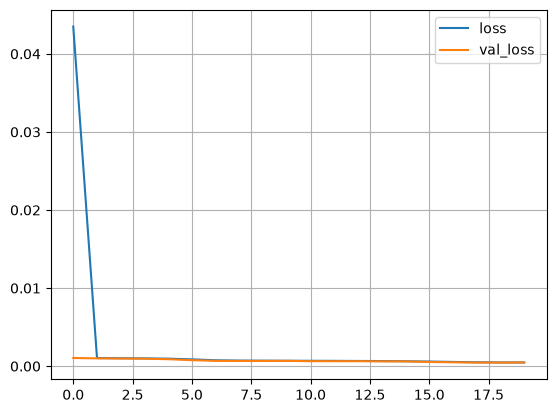

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()